Database location: C:\Users\Lenovo\Documents\Sharif\finall_project\observation.db

        Welcome to Observer Log         

1. Add Observation
2. Show Observation
3. Maximum exposure
4. Minimum Exposure
5. Total exposure
6. Average exposure
7. Search observation
8. Save to file
9. Show graph
10.Save to database
0. Exit


Choose: 2


 Observation >>> 1
 Target: M33
 exposure: 130.0
 observer : negar
 filter: V
 Observation >>> 2
 Target: M53
 exposure: 180.0
 observer : Reza
 filter: H
 Observation >>> 3
 Target: M67
 exposure: 110.0
 observer : Sahar
 filter: H

        Welcome to Observer Log         

1. Add Observation
2. Show Observation
3. Maximum exposure
4. Minimum Exposure
5. Total exposure
6. Average exposure
7. Search observation
8. Save to file
9. Show graph
10.Save to database
0. Exit


Choose: 3


Max exposure time is 180.0 sec

        Welcome to Observer Log         

1. Add Observation
2. Show Observation
3. Maximum exposure
4. Minimum Exposure
5. Total exposure
6. Average exposure
7. Search observation
8. Save to file
9. Show graph
10.Save to database
0. Exit


...

Choose: 6


Average exposure time is 140.0 sec

        Welcome to Observer Log         

1. Add Observation
2. Show Observation
3. Maximum exposure
4. Minimum Exposure
5. Total exposure
6. Average exposure
7. Search observation
8. Save to file
9. Show graph
10.Save to database
0. Exit


Choose: 7
Target:  m33


Observation found

Target: M33
Exposure: 130.0
Observer: negar
Filter: V

        Welcome to Observer Log         

1. Add Observation
2. Show Observation
3. Maximum exposure
4. Minimum Exposure
5. Total exposure
6. Average exposure
7. Search observation
8. Save to file
9. Show graph
10.Save to database
0. Exit


Choose: 9


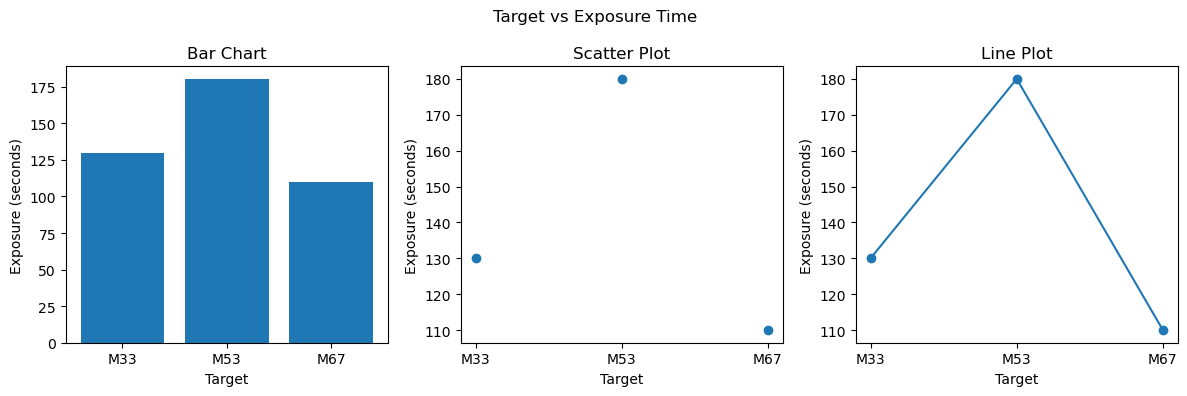


        Welcome to Observer Log         

1. Add Observation
2. Show Observation
3. Maximum exposure
4. Minimum Exposure
5. Total exposure
6. Average exposure
7. Search observation
8. Save to file
9. Show graph
10.Save to database
0. Exit


Choose: 0


In [1]:
from visualization import show_graph
import sqlite3
import csv
from observation import Observation
import numpy as np
from database import save_observations_to_db , load_observations_from_db
import os
print("Database location:", os.path.abspath("observation.db"))

observations =[]

def add_observation():
    target = input("Target: ")
    try: 
        exposure = float(input("Exposure time(Second)"))
    except ValueError:
        print("Exposure time should be a int or float")
        return 
    observer = input("Name of observer:")
    filt = input("Filter name: ")
    obs = Observation(target, observer, filt, exposure)
    observations.append(obs)
    print("Observation added Succesfully")
def show_observation():
    if len(observations) == 0:
        print("No Observation found")
        return
    else:
        for i, obs in enumerate(observations):
            print(f" Observation >>> {i + 1}\n Target: {obs.target}")
            print(f" exposure: {obs.exposure}")
            print(f" observer : {obs.observer}")
            print(f" filter: {obs.filter}")
def search_observation():
    user = input("Target: ")
    found = False
    for obs in observations:
        if user.lower() == obs.target.lower():
            print("Observation found\n")
            print(f"Target: {obs.target}")
            print(f"Exposure: {obs.exposure}")
            print(f"Observer: {obs.observer}")
            print(f"Filter: {obs.filter}")
            found = True
    if not found:
        print("No target name found")
    
def max_exposure():
    if len(observations) == 0:
        print("No observations available.")
        return
        
    exposures = np.array([obs.exposure for obs in observations])
    maxe = np.max(exposures)
    print(f"Max exposure time is {maxe} sec")
def min_exposure():
    if len(observations) == 0:
        print("No observations available.")
        return

    exposures = np.array([obs.exposure for obs in observations])
    mine = np.min(exposures)
    print(f"Min exposure time is {mine} sec")
def total_exposure():
    if len(observations) == 0:
        print("No observations available.")
        return

    exposures = np.array([obs.exposure for obs in observations])
    total = np.sum(exposures)
    print(f"Total exposure time is {total} sec")
def average_exposure():
    if len(observations) == 0:
        print("No observations available.")
        return

    exposures = np.array([obs.exposure for obs in observations])
    aver = np.average(exposures)
    print(f"Average exposure time is {aver} sec")
def save_to_file():
    filename = input("Enter your file name:")
    with open(f"{filename}.csv", "w", newline="") as csvfile:
        fieldnames = [
            "target",
            "observer",
            "exposure(Second)",
            "filter"
            ]
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

        writer.writeheader()
        for obs in observations:
            row = {
                "target": obs.target,
                "observer":obs.observer,
                "exposure(Second)":obs.exposure,
                "filter":obs.filter
                
            }
            writer.writerow(row)
conn = sqlite3.connect("observation.db")
observations = load_observations_from_db(conn)
    
while True:
    print("=" * 40)
    print()
    print("Welcome to Observer Log".center(40))
    print()
    print("=" * 40)
    print("1. Add Observation")
    print("2. Show Observation")
    print("3. Maximum exposure")
    print("4. Minimum Exposure")
    print("5. Total exposure")
    print("6. Average exposure")
    print("7. Search observation")
    print("8. Save to file")
    print("9. Show graph")
    print("10.Save to database")
    print("0. Exit")
    choice = input("Choose:")
    if choice == "1":
        add_observation()
    elif choice == "2":
        show_observation()
    elif choice == "3":
        max_exposure()
    elif choice == "4":
        min_exposure()
    elif choice == "5":
        total_exposure()
    elif choice == "6":
        average_exposure()
    elif choice == "7":
        search_observation()
    elif choice == "8":  
        save_to_file()
    elif choice == "9":
        show_graph(observations)
    elif choice == "10":
        save_observations_to_db(observations, conn)        
    elif choice == "0":
        break
    else: 
        print("Please select 0 to 10")        
conn.close()     

In [ ]:
code=('''
from observation import Observation


# تکراری‌ها را ذخیره نمی‌کند
def save_observations_to_db(observations, conn):
    cursor = conn.cursor()

    cursor.execute("""
        CREATE TABLE IF NOT EXISTS observations (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            target TEXT,
            observer TEXT,
            filter_name TEXT,
            exposure REAL
        )
    """)

    saved_count = 0
    duplicate_count = 0

    for obs in observations:
        cursor.execute("""
            SELECT id FROM observations
            WHERE target = ?
              AND observer = ?
              AND filter_name = ?
              AND exposure = ?
        """, (
            obs.target,
            obs.observer,
            obs.filter,
            obs.exposure
        ))

        if cursor.fetchone() is not None:
            duplicate_count += 1
            continue

        cursor.execute("""
            INSERT INTO observations
            (target, observer, filter_name, exposure)
            VALUES (?, ?, ?, ?)
        """, (
            obs.target,
            obs.observer,
            obs.filter,
            obs.exposure
        ))

        saved_count += 1

    conn.commit()

    print(f"{saved_count} new observations saved.")

    if duplicate_count > 0:
        print(f"{duplicate_count} duplicate observations skipped.")


# اطلاعات قبلی را از دیتابیس می‌خواند
def load_observations_from_db(conn):
    cursor = conn.cursor()

    cursor.execute("""
        CREATE TABLE IF NOT EXISTS observations (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            target TEXT,
            observer TEXT,
            filter_name TEXT,
            exposure REAL
        )
    """)

    cursor.execute("""
        SELECT target, observer, filter_name, exposure
        FROM observations
    """)

    rows = cursor.fetchall()
    observations = []

    for row in rows:
        target, observer, filter_name, exposure = row

        obs = Observation(
            target,
            observer,
            filter_name,
            exposure
        )

        observations.append(obs)

    return observations
''')